In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

In [2]:
def attention_forward(x, Wq, Wk, Wv):
    # x: (T, C)   T = positions in the context, C = embedding size
    # Wq, Wk, Wv: (C, H)   H = head size
    # 1. q, k, v = x @ each matrix                      -> (T, H) each
    q = x @ Wq
    k = x @ Wk
    v = x @ Wv
    # 2. scores = q @ k.T                               -> (T, T)  scores[t][s] = q[t] · k[s]
    scores = q @ k.T
    # 3. scores = scores / sqrt(H)                      (keeps numbers small so softmax isn't too sharp)
    scores = scores/np.sqrt(Wk.shape[1])
    # 4. for every t, s with s > t: scores[t][s] = -inf (the causal mask, two for loops are fine)
    for t in range(scores.shape[0]):
        for s in range(scores.shape[1]):
            if s > t:
                scores[t][s] = -np.inf
    # 5. weights = softmax on each row                  (subtract the row max first, like in chat.py)
    T = scores.shape[0]
    weights = np.zeros(scores.shape)
    for t in range(T):
        row = scores[t]                      # the scores of position t
        biggest = row.max()                  # A: the biggest score in this row
        exps = np.exp(row - biggest)         # A + B: subtract it from every number, then exp of every number
        weights[t] = exps / exps.sum()       # C: divide every number by the sum of the row
    # 6. out = weights @ v                              -> (T, H)
    out = weights @ v
    return out, weights

out shape: (6, 4)  weights shape: (6, 6)
each row sums to 1: True
no looking into the future: True
position 0 can only see itself: [1. 0. 0. 0. 0. 0.]


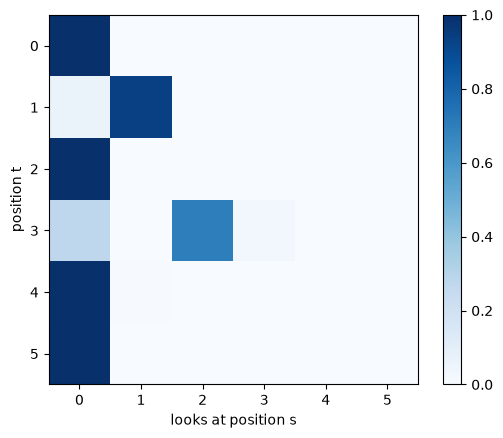

In [3]:
np.random.seed(0)
T, C, H = 6, 8, 4
x = np.random.randn(T, C)
Wq = np.random.randn(C, H)
Wk = np.random.randn(C, H)
Wv = np.random.randn(C, H)

out, weights = attention_forward(x, Wq, Wk, Wv)
print("out shape:", out.shape, " weights shape:", weights.shape)      # (6, 4) (6, 6)
print("each row sums to 1:", np.allclose(weights.sum(axis=1), 1))
print("no looking into the future:", np.allclose(np.triu(weights, k=1), 0))
print("position 0 can only see itself:", weights[0])

import matplotlib.pyplot as plt
plt.imshow(weights, cmap="Blues")
plt.xlabel("looks at position s"); plt.ylabel("position t")
plt.colorbar(); plt.show()

In [4]:
def embed_with_positions(ids, token_table, position_table):
    # ids: list of character ids, one per position     (length T)
    # token_table: (vocab_size, C)    one row per character
    # position_table: (max_T, C)      one row per position
    T = len(ids)
    C = token_table.shape[1]
    x = np.zeros((T, C))
    for i in range(T):
        x[i] = token_table[ids[i]] + position_table[i]
    return x

In [5]:
np.random.seed(0)
C = 4
token_table = np.random.randn(10, C)
position_table = np.random.randn(8, C)

ids = [3, 5, 3]                    # the same character (3) at positions 0 and 2
x = embed_with_positions(ids, token_table, position_table)
print("shape:", x.shape)                                         # (3, 4)
print("same char, different vectors:", not np.allclose(x[0], x[2]))   # True
print("correct sum:", np.allclose(x[1], token_table[5] + position_table[1]))  # True

# now attention on top of it
Wq = np.random.randn(C, 4); Wk = np.random.randn(C, 4); Wv = np.random.randn(C, 4)
out, weights = attention_forward(x, Wq, Wk, Wv)
print(np.round(weights, 2))

shape: (3, 4)
same char, different vectors: True
correct sum: True
[[1.   0.   0.  ]
 [0.89 0.11 0.  ]
 [0.03 0.11 0.87]]


In [6]:
chars = np.load("../checkpoints/slate.npz")["chars"]   # same characters as Slate
vocab_size = len(chars)
C = 16              # size of every vector
H = 16              # head size
context_size = 32   # Quartz sees the last 32 characters

np.random.seed(42)
np.savez("../checkpoints/quartz.npz",
    token_table=np.random.randn(vocab_size, C),        # one row per character
    position_table=np.random.randn(context_size, C),   # one row per position
    Wq=np.random.randn(C, H) * 0.3,
    Wk=np.random.randn(C, H) * 0.3,
    Wv=np.random.randn(C, H) * 0.3,
    W_out=np.random.randn(H, vocab_size) * 0.3,        # the matching layer: one column per character
    b_out=np.zeros(vocab_size),
    chars=chars)
print("saved")

saved


In [ ]:
from alexgpt.tensor import Tensor, add, matmul

np.random.seed(0)
x = Tensor(np.random.randn(3, 4))
y = Tensor(np.random.randn(3, 4))
W = Tensor(np.random.randn(4, 2))

def forward():
    out = matmul(add(x, y), W)          # (x + y) @ W
    return out

out = forward()
out.backward()                          # pretend the loss is the sum of all cells of out

# numerical gradient for x
epsilon = 1e-6
numeric = np.zeros(x.data.shape)
for i in range(x.data.shape[0]):
    for j in range(x.data.shape[1]):
        old = x.data[i][j]
        x.data[i][j] = old + epsilon
        plus = forward().data.sum()
        x.data[i][j] = old - epsilon
        minus = forward().data.sum()
        x.data[i][j] = old
        numeric[i][j] = (plus - minus) / (2 * epsilon)

print("x.grad correct:", np.allclose(x.grad, numeric))
print("y.grad equals x.grad:", np.allclose(y.grad, x.grad))   # both got the same, whole blame

x.grad correct: True
y.grad equals x.grad: False
